# Learning Without Losing Everything

*The Mathematics of Machine Intelligence · Chapter 7*

Measure how one lesson disturbs another, what mixing old and new buys, and what savings and competing expectations say about forgetting.

These pages illustrate the mathematics. Read the saved figures and calculations in order, or open [the interactive browser edition](reader.html) to change the examples. No code editing is needed. Every figure is computed from the chapter's own equations or from a disclosed simulation; a simulation is not a measurement, and the mathematics of a brain is a model.

Ask which old items share features with the new lesson, how large the step and the new error are, and whether the old answer actually became worse against its own target. Use the interference card for one step, the three-item card for the price and the point of overlap, the schedule card for focused against mixed training in a toy, the savings card to ask whether apparent loss is cheap to restore, and the mixture card for keeping competing expectations. Say that none of these is a measurement of a brain or of a deep network.

<details><summary>Reproducing these calculations</summary>

The optional calculation cells use Python with NumPy and Matplotlib. All inputs, random seeds and functions are included in this file. The figures below are saved, so running these cells is optional.

</details>

In [1]:
import io
import math
import re
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
from cycler import cycler
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11, 'axes.titlesize': 13, 'axes.labelsize': 11, 'xtick.labelsize': 10, 'ytick.labelsize': 10, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#7d8588', 'axes.labelcolor': '#172a3b', 'text.color': '#172a3b', 'xtick.color': '#52606b', 'ytick.color': '#52606b', 'figure.facecolor': 'white', 'axes.facecolor': 'white', 'savefig.facecolor': 'white', 'grid.alpha': 0.2, 'lines.linewidth': 2, 'svg.fonttype': 'path', 'axes.unicode_minus': False})
plt.rcParams['axes.prop_cycle'] = cycler(color=['#136f75', '#b77518', '#334c72', '#aa4e37', '#677341'])

def clean_display_text(text):
    """Remove signed zero only after an explicitly formatted value rounds to zero."""
    return re.sub(r"(?<![\w.])-(?:0+(?:\.0*)?|\.0+)(?:[eE][+-]?\d+)?(?![\w.])", "0", text)


def display_value(value):
    """One display policy for readers, saved notebooks and skill references."""
    if hasattr(value, "item") and getattr(value, "size", 1) == 1:
        value = value.item()
    if isinstance(value, float):
        if not math.isfinite(value):
            raise ValueError("Return undefined or infinity as a labeled string, not a nonfinite JSON value")
        return "0" if value == 0 else f"{value:.6g}"
    if isinstance(value, str):
        return clean_display_text(value)
    if isinstance(value, (list, tuple)):
        opening, closing = ("(", ")") if isinstance(value, tuple) else ("[", "]")
        return opening + ", ".join(str(display_value(v)) for v in value) + closing
    if isinstance(value, dict):
        return "{" + ", ".join(str(k) + ": " + str(display_value(v)) for k, v in value.items()) + "}"
    return value


"""Chapter 7, Learning Without Losing Everything: executable mathematics and reader-facing teaching content."""
import math
import numpy as np
import matplotlib.pyplot as plt
NAVY = '#17324d'
TEAL = '#147d86'
GOLD = '#d8a23c'
DARK_GOLD = '#8a5a0f'
TERRA = '#bf6045'
GREY = '#7d8588'

def sig(value, digits=3):
    """Three significant figures; values that are zero up to round-off show as 0."""
    value = float(value)
    if abs(value) < 1e-12:
        return '0'
    return f'{value:.{digits}g}'

def panels():
    fig, axes = plt.subplots(1, 2, figsize=(8, 4.2), layout='constrained')
    for ax in axes:
        ax.grid(alpha=0.15)
    return (fig, axes)

def tag(ax, x, y, text, **kwargs):
    """A label with a white backing so it stays legible over lines."""
    kwargs.setdefault('fontsize', 11)
    kwargs.setdefault('ha', 'center')
    ax.text(x, y, text, bbox={'facecolor': 'white', 'edgecolor': 'none', 'pad': 1.5, 'alpha': 0.9}, **kwargs)

def ring(ax, x, y):
    ax.plot([x], [y], marker='o', markersize=11, markerfacecolor='none', markeredgecolor=NAVY, markeredgewidth=2.2, zorder=6)

def feature_pair(overlap):
    """Two unit-length feature lists, A and B, whose dot product is the chosen overlap."""
    if not -1.0 <= overlap <= 1.0:
        raise ValueError('The overlap of two unit-length feature lists must lie between -1 and 1.')
    xa = np.array([1.0, 0.0])
    xb = np.array([overlap, math.sqrt(max(0.0, 1.0 - overlap * overlap))])
    return (xa, xb)

def answer_shift(eta, new_error, dot):
    """The chapter's identity: change in A's answer = -eta x e_B x (x_A . x_B)."""
    return -eta * new_error * dot

def gradient_step(w, x, target, eta):
    """One update on half the squared miss for item (x, target); returns the new weights and the error before."""
    error = float(np.dot(w, x) - target)
    return (w - eta * error * x, error)
ETAS = [0.1, 0.25, 0.5, 1.0]
OVERLAPS_D01 = [-1, -0.5, 0, 0.5, 1]
NEW_ERROR = 2.0
LEARNER_START = np.array([1.0, 0.5])

def one_step_update(eta, overlap, new_error=NEW_ERROR):
    """Carry out the real update on a two-weight learner and report A's answer before and after.

    The target for B is chosen so the learner's error on B before the update is exactly new_error.
    """
    xa, xb = feature_pair(overlap)
    w = LEARNER_START.copy()
    target_b = float(np.dot(w, xb) - new_error)
    w_new, error = gradient_step(w, xb, target_b, eta)
    return {'old_answer': float(np.dot(w, xa)), 'new_answer': float(np.dot(w_new, xa)), 'error': error, 'weights_before': w, 'weights_after': w_new}

def one_step_picture(eta=0.5, overlap=0.5):
    out = one_step_update(eta, overlap)
    shift = out['new_answer'] - out['old_answer']
    fig, ax = panels()
    vals = [out['old_answer'], out['new_answer']]
    bars = ax[0].bar([0, 1], vals, color=[GREY, TEAL], width=0.55)
    for b, v in zip(bars, vals):
        tag(ax[0], b.get_x() + b.get_width() / 2, v + (0.12 if v >= 0 else -0.12), sig(v), fontsize=11, va='bottom' if v >= 0 else 'top')
    ax[0].axhline(0, color=GREY, linewidth=0.8)
    ax[0].set_xticks([0, 1])
    ax[0].set_xticklabels(["A's answer\nbefore", "A's answer\nafter one update on B"], fontsize=9)
    ax[0].set(ylim=(-1.7, 3.5), ylabel="the learner's answer for old item A", title=f'Step {eta:g}, overlap {overlap:g}, new error {sig(NEW_ERROR)}')
    grid = np.linspace(-1, 1, 41)
    for e, col in zip(ETAS, [GREY, GOLD, TERRA, NAVY]):
        ax[1].plot(grid, [answer_shift(e, NEW_ERROR, g) for g in grid], color=col, linewidth=2.8 if e == eta else 1.2, label=f'step {e:g}')
    ring(ax[1], overlap, shift)
    ax[1].axhline(0, color=GREY, linewidth=0.8)
    ax[1].axvline(0, color=GREY, linewidth=0.8)
    ax[1].set(xlabel="overlap: dot product of A's and B's features", ylabel="change in A's answer", ylim=(-2.4, 2.4), title='The shift is a straight line in the overlap')
    ax[1].legend(fontsize=8, loc='lower left')
    metrics = {"A's answer before": sig(out['old_answer']), "A's answer after": sig(out['new_answer']), "Change in A's answer": sig(shift), 'Change as a share of the new error': sig(shift / NEW_ERROR)}
    summary = f"One update on a new item whose error is {sig(NEW_ERROR)}, with step {eta:g} and overlap {overlap:g}, moves A's answer from {sig(out['old_answer'])} to {sig(out['new_answer'])}, a change of {sig(shift)}. With an overlap of 0 the change would be 0. This is a linear learner and one step, and a change is not yet forgetting."
    calc = f'Change = -step x error x overlap = -{eta:g} x {sig(NEW_ERROR)} x ({overlap:g}) = {sig(answer_shift(eta, NEW_ERROR, overlap))}. A real update of the weights gives the same {sig(shift)}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})
OVERLAPS_D02 = [0, 0.25, 0.5, 0.75]
STEPS_D02 = [0.25, 0.5, 1.0]

def three_item_toy(overlap, step):
    """Items A (old, right answer 1), B (new, right answer -1) and C (a neighbor of A, right answer 1).

    The learner's weights equal A's feature list, so it answers 1 for A, and `overlap` for both B and C.
    C's answer after the update is not computed: it depends on how C and B overlap, which the chapter leaves open.
    """
    xa, xb = feature_pair(overlap)
    w = xa.copy()
    w_new, error_b = gradient_step(w, xb, -1.0, step)
    return {'b_error_before': error_b, 'a_before': float(w @ xa), 'a_after': float(w_new @ xa), 'b_before': float(w @ xb), 'b_after': float(w_new @ xb), 'c_before': overlap, 'a_error_after': abs(1.0 - float(w_new @ xa)), 'c_error_before': 1.0 - overlap}

def price_and_point_picture(overlap=0.5, step=1.0):
    t = three_item_toy(overlap, step)
    fig, ax = panels()
    rows = [('A (old)', 2, 1.0, t['a_before'], t['a_after']), ('B (new)', 1, -1.0, t['b_before'], t['b_after']), ('C (neighbor of A)', 0, 1.0, t['c_before'], None)]
    for name, y, right, before, after in rows:
        ax[0].plot([-1, 1], [y, y], color=GREY, linewidth=0.8, alpha=0.6, zorder=1)
        ax[0].plot([right], [y], marker='D', markersize=13, markerfacecolor='none', markeredgecolor=DARK_GOLD, markeredgewidth=2, linestyle='none', zorder=2)
        ax[0].plot([before], [y], marker='o', markersize=7, color=NAVY, linestyle='none', zorder=4)
        tag(ax[0], before, y - 0.3, sig(before), fontsize=8, va='top')
        if after is not None:
            if abs(after - before) > 1e-09:
                ax[0].annotate('', xy=(after, y), xytext=(before, y), arrowprops={'arrowstyle': '->', 'color': TEAL, 'linewidth': 2}, zorder=3)
            ax[0].plot([after], [y], marker='o', markersize=7, color=TEAL, linestyle='none', zorder=5)
            tag(ax[0], after, y + 0.3, sig(after), fontsize=8, va='bottom', color=TEAL)
        else:
            tag(ax[0], 1.4, y + 0.3, 'after: left open', fontsize=8, ha='right', va='bottom', color=GREY)
    ax[0].plot([], [], marker='D', markersize=8, markerfacecolor='none', markeredgecolor=DARK_GOLD, linestyle='none', label='right answer')
    ax[0].plot([], [], marker='o', color=NAVY, linestyle='none', label='before')
    ax[0].plot([], [], marker='o', color=TEAL, linestyle='none', label='after')
    ax[0].legend(fontsize=8, loc='upper center', ncol=3)
    ax[0].set_yticks([0, 1, 2])
    ax[0].set_yticklabels(['C (neighbor)', 'B (new)', 'A (old)'], fontsize=9)
    ax[0].set(xlim=(-1.45, 1.45), ylim=(-0.7, 3.1), xlabel="the learner's answer", title=f'One update on B, overlap {overlap:g}, step {step:g}')
    grid = np.linspace(0, 0.9, 46)
    for s, col in zip(STEPS_D02, [GREY, GOLD, NAVY]):
        ax[1].plot(grid, [s * (1 + g) * g for g in grid], color=col, linewidth=2.8 if s == step else 1.2, label=f"A's error after, step {s:g}")
    ax[1].plot(grid, 1 - grid, color=TEAL, linewidth=2.4, linestyle='dashed', label="C's starting error")
    ring(ax[1], overlap, t['a_error_after'])
    ring(ax[1], overlap, t['c_error_before'])
    ax[1].set(xlabel='overlap of A with B and with C', ylabel='distance from the right answer', ylim=(-0.05, 1.8), title='Overlap costs A and helps C')
    ax[1].legend(fontsize=8, loc='upper center')
    metrics = {"A's answer after": sig(t['a_after']), "A's error after": sig(t['a_error_after']), "C's answer before any update": sig(t['c_before']), "C's error before any update": sig(t['c_error_before'])}
    summary = f"At overlap {overlap:g} and step {step:g}, one update on B moves A's answer from 1 to {sig(t['a_after'])}, an error of {sig(t['a_error_after'])}. C starts {sig(t['c_error_before'])} from its right answer, not 1, because it shares with A. C's change after the update is left open, as in the chapter."
    calc = f"B's error before = {overlap:g} + 1 = {sig(1 + overlap)}. A's answer after = 1 - {step:g} x {sig(1 + overlap)} x {overlap:g} = {sig(t['a_after'])}. C's starting answer = {overlap:g}, so its error is 1 - {overlap:g} = {sig(1 - overlap)}."
    return (fig, metrics, {'summary': summary, 'calculation': calc})
SCHEDULES = ['focused', 'interleaved']
OVERLAPS_D03 = [0.25, 0.5, 0.75]
RATES_D03 = [0.1, 0.25, 0.5]
N_UPDATES = 60
B_TARGET_ERROR = 0.1

def train(schedule, overlap, rate, n=N_UPDATES):
    """Error on B (new) and on A (old) after each update, starting from a learner that knows A exactly.

    Focused: every update is on B. Interleaved: updates alternate B, A, B, A, ... so half the updates go to A.
    """
    if schedule not in SCHEDULES:
        raise ValueError("schedule must be 'focused' or 'interleaved'")
    xa, xb = feature_pair(overlap)
    w = xa.copy()
    err_b = [abs(float(w @ xb) + 1.0)]
    err_a = [abs(float(w @ xa) - 1.0)]
    for k in range(n):
        if schedule == 'focused' or k % 2 == 0:
            w, _ = gradient_step(w, xb, -1.0, rate)
        else:
            w, _ = gradient_step(w, xa, 1.0, rate)
        err_b.append(abs(float(w @ xb) + 1.0))
        err_a.append(abs(float(w @ xa) - 1.0))
    return (np.array(err_b), np.array(err_a))

def first_below(errors, threshold=B_TARGET_ERROR):
    """Number of updates until the error is under the threshold, or None."""
    for k, e in enumerate(errors):
        if e < threshold:
            return k
    return None

def schedule_picture(schedule='focused', overlap=0.5, rate=0.25):
    runs = {s: train(s, overlap, rate) for s in SCHEDULES}
    err_b, err_a = runs[schedule]
    fig, ax = panels()
    xs = np.arange(N_UPDATES + 1)
    for s, col in zip(SCHEDULES, [TERRA, TEAL]):
        thick = 2.8 if s == schedule else 1.2
        ax[0].plot(xs, runs[s][0], color=col, linewidth=thick, label=s)
        ax[1].plot(xs, runs[s][1], color=col, linewidth=thick, label=s)
    ax[0].set(xlabel='updates so far (all kinds)', ylabel='error on the new item B', ylim=(-0.05, 1.9), title='The new item is learned')
    ax[1].set(xlabel='updates so far (all kinds)', ylabel='error on the old item A', ylim=(-0.05, 1.5), title='The old item is harmed, or kept')
    ax[0].legend(fontsize=8, loc='upper right')
    ax[1].legend(fontsize=8, loc='upper right')
    steps_to_b = first_below(err_b)
    steps_text = str(steps_to_b) if steps_to_b is not None else f'not within {N_UPDATES}'
    metrics = {'B error after 40 updates': sig(err_b[40]), 'A error after 40 updates': sig(err_a[40]), f'Updates until B error is under {B_TARGET_ERROR:g}': steps_text, f'Largest A error in {N_UPDATES} updates': sig(err_a.max())}
    if schedule == 'focused':
        story = f'B is learned fast and A is left with an error of {sig(err_a[-1])}.'
    else:
        story = f"half the updates go to A, so B is learned more slowly per update, and A's error ends at {sig(err_a[-1])}."
    summary = f'In this two-item toy with overlap {overlap:g} and rate {rate:g}, {schedule} training: {story} It is a companion toy for the trade in the penguin network, not a copy of that network.'
    calc = f"Each update subtracts rate x error x the item's features from the weights. Focused, with unit-length features, shrinks B's error by (1 - {rate:g}) each update and leaves A at {sig(overlap * (1 + overlap))} off in the limit. Interleaved settles at the weights that answer both exactly."
    return (fig, metrics, {'summary': summary, 'calculation': calc})
SAVINGS_CASES = {'chapter example': 0.2, 'Ebbinghaus minutes': 0.58, 'Ebbinghaus one month': 0.21, 'Murre-Dros 31 days': 0.04, 'Murre-Dros adjusted': 0.14, 'one twentieth': 0.95}
L0_CHOICES = [10, 25, 50, 100]

def savings(first_effort, relearn_effort):
    """S = (L0 - Lt) / L0, with both efforts in the same units."""
    if first_effort <= 0:
        raise ValueError('The first-learning effort must be positive.')
    return (first_effort - relearn_effort) / first_effort

def relearn_effort_for(s, first_effort):
    """The relearning effort that gives savings s on the plain ratio: Lt = L0 (1 - s)."""
    return first_effort * (1.0 - s)

def savings_picture(case='chapter example', l0=25):
    s_case = SAVINGS_CASES[case]
    lt = relearn_effort_for(s_case, l0)
    s = savings(l0, lt)
    fig, ax = panels()
    ax[0].bar([0, 1], [l0, lt], color=[NAVY, GOLD], width=0.55)
    tag(ax[0], 0, l0 * 1.03, sig(l0), fontsize=11, va='bottom')
    if lt > 0.25 * l0:
        tag(ax[0], 1, lt / 2, sig(lt), fontsize=11, va='center')
    else:
        tag(ax[0], 1, lt + l0 * 0.03, sig(lt), fontsize=11, va='bottom')
    saved = l0 - lt
    if saved > 1e-09:
        ax[0].bar([1], [saved], bottom=[lt], width=0.55, color='none', edgecolor=TEAL, hatch='//', linewidth=1.2)
        tag(ax[0], 1.42, lt + saved / 2, f'saved {sig(saved)}', fontsize=9, ha='left', va='center', color=TEAL)
    ax[0].set_xticks([0, 1])
    ax[0].set_xticklabels(['learning the list\nthe first time', 'relearning it\nafter the delay'], fontsize=9)
    ax[0].set(xlim=(-0.5, 2.0), ylim=(0, l0 * 1.22), ylabel='effort (same units, same standard)', title=f'{case}: S = {sig(s)}')
    grid = np.linspace(0, 1, 50)
    ax[1].plot(grid, 1 - grid, color=NAVY, linewidth=2)
    for name, val in SAVINGS_CASES.items():
        ax[1].plot([1 - val], [val], marker='o', markersize=7, color=GREY, linestyle='none', zorder=4)
    ring(ax[1], 1 - s, s)
    tag(ax[1], 0.5, 0.88, 'each dot is one case from the chapter', fontsize=8, color=GREY)
    ax[1].set(xlabel='relearning effort as a share of the first learning', ylabel='savings S', xlim=(-0.03, 1.05), ylim=(-0.05, 1.05), title='Savings falls as relearning costs more')
    metrics = {'Savings S': sig(s), 'Effort to learn first time': sig(l0), 'Effort to relearn': sig(lt), 'Effort saved': sig(saved)}
    summary = f"With a first learning effort of {sig(l0)}, savings of {sig(s)} means relearning takes {sig(lt)}, so {sig(saved)} of the first effort is saved. For the reported savings values, the efforts are the companion's scaling, not data."
    calc = f'S = (L0 - Lt) / L0 = ({sig(l0)} - {sig(lt)}) / {sig(l0)} = {sig(s)}. Equivalently Lt = L0 x (1 - S) = {sig(l0)} x {sig(1 - s)} = {sig(lt)}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})
WEIGHTS_OLD = [0, 0.2, 0.5, 0.8, 1]
NEW_PREDICTS = [0, 0.1, 0.25, 0.5]
OLD_PREDICTS = 1.0

def mixture_prediction(weight_old, p_old=OLD_PREDICTS, p_new=0.0):
    """Combined prediction = w_old x p_old + (1 - w_old) x p_new."""
    if not 0 <= weight_old <= 1:
        raise ValueError('A weight on the old cause must lie between 0 and 1.')
    return weight_old * p_old + (1 - weight_old) * p_new

def latent_cause_picture(weight_old=0.8, new_predicts=0):
    w_new = 1 - weight_old
    p = mixture_prediction(weight_old, OLD_PREDICTS, new_predicts)
    fig, ax = panels()
    vals = [OLD_PREDICTS, new_predicts, p]
    bars = ax[0].bar([0, 1, 2], vals, color=[NAVY, GOLD, TEAL], width=0.6)
    for b, v in zip(bars, vals):
        tag(ax[0], b.get_x() + b.get_width() / 2, v + 0.03, sig(v), fontsize=11, va='bottom')
    ax[0].set_xticks([0, 1, 2])
    ax[0].set_xticklabels([f'old cause\nweight {sig(weight_old)}', f'new cause\nweight {sig(w_new)}', 'combined\nprediction'], fontsize=9)
    ax[0].set(ylim=(0, 1.2), ylabel='predicted chance of shock', title='Neither expectation is deleted')
    grid = np.linspace(0, 1, 41)
    for q, col in zip(NEW_PREDICTS, [NAVY, GOLD, TERRA, GREY]):
        ax[1].plot(grid, [mixture_prediction(g, OLD_PREDICTS, q) for g in grid], color=col, linewidth=2.8 if q == new_predicts else 1.2, label=f'new cause predicts {q:g}')
    ring(ax[1], weight_old, p)
    ax[1].set(xlabel='weight on the old cause', ylabel='combined prediction', ylim=(-0.05, 1.1), title='A change of weights moves the prediction')
    ax[1].legend(fontsize=8, loc='upper left')
    metrics = {'Weight on the old cause': sig(weight_old), 'Weight on the new cause': sig(w_new), 'Combined prediction': sig(p), "New cause's own prediction": sig(new_predicts)}
    summary = f"With weight {sig(weight_old)} on the old cause, which predicts shock with probability 1, and {sig(w_new)} on a new cause that predicts {sig(new_predicts)}, the combined prediction is {sig(p)}. Changing the weights moves the prediction without changing either cause's own expectation. The weights are set by hand here, not inferred."
    calc = f'{sig(weight_old)} x 1 + {sig(w_new)} x {sig(new_predicts)} = {sig(p)}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})

## C07-D01: How far does one lesson on a new item shift an old answer?

If a linear learner takes one update on a new item B, how far does its answer for an old item A move?

The update subtracts step x error x B's features from the weights. A's answer is the weights dotted with A's features, so the change in A's answer is that same subtraction dotted with A's features: step x error x the overlap of A and B, with a minus sign.

$$
\Delta\hat y_A=-\eta\,e_B\,(\mathbf x_A\cdot\mathbf x_B)
$$

$$
\mathbf w_{\text{new}}=\mathbf w-\eta\,e_B\,\mathbf x_B
$$

**Symbols:** Delta y_A: the change in the learner's answer for old item A; eta: the step size, how far one update moves the weights; e_B: the new item's error before the update: the learner's answer minus the right answer (2 here); x_A . x_B: the overlap: the dot product of A's and B's feature lists, between -1 and 1 for unit-length lists

**Predict before looking:** The step is 0.5, the new item's error is 2 and the overlap is 0.5. Predict how far A's answer moves and in which direction.

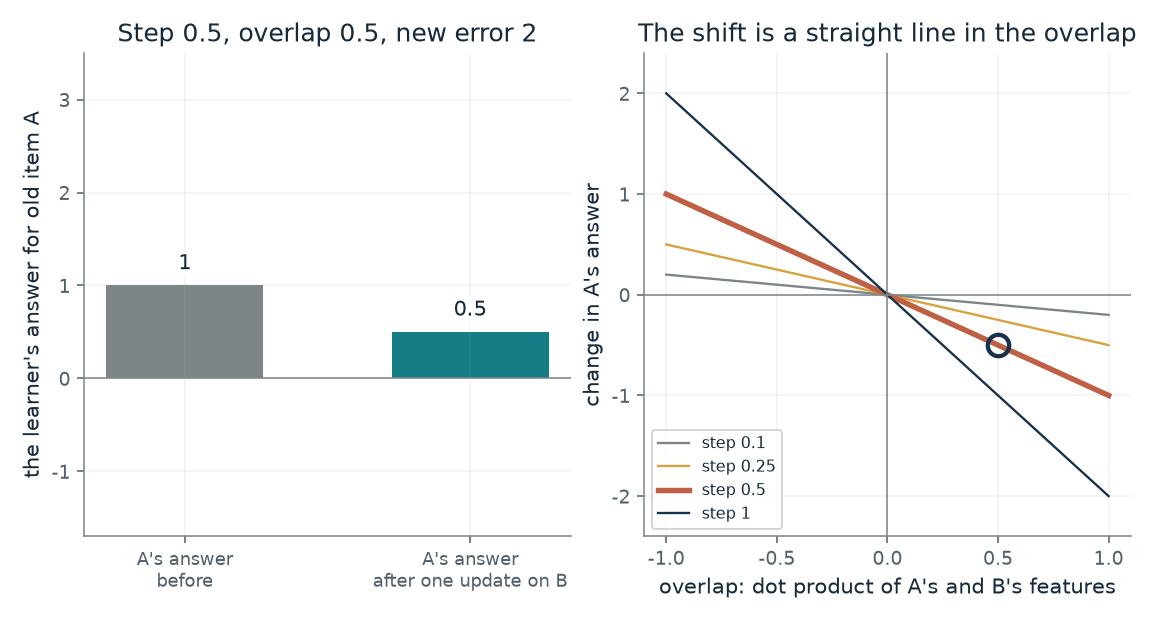

- **A's answer before:** 1
- **A's answer after:** 0.5
- **Change in A's answer:** -0.5
- **Change as a share of the new error:** -0.25

One update on a new item whose error is 2, with step 0.5 and overlap 0.5, moves A's answer from 1 to 0.5, a change of -0.5. With an overlap of 0 the change would be 0. This is a linear learner and one step, and a change is not yet forgetting.

Change = -step x error x overlap = -0.5 x 2 x (0.5) = -0.5. A real update of the weights gives the same -0.5.

In [2]:
figure, values, explanation = one_step_picture(**{'eta': 0.5, 'overlap': 0.5})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='How far does one lesson on a new item shift an old answer?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Step size = 0.5, Overlap of A and B = 0.5: A's answer moves by -0.5, a quarter of the new error of 2, in the opposite direction from the error. With an overlap of 0 it does not move at all, and with an overlap of -1 it moves up by 1.

**Takeaway:** The shift is the step size times the new error times the overlap, so items that share nothing with the new lesson are left alone and items that share more are moved more.

**Why it matters:** This is the smallest picture of how learning one thing can disturb another: the same weights answer both, so a push on one item reaches the other through the features they share.

**In brains and behavior:** H.M. showed the trouble from the other side: he could not form new memories of the events of a day while much older knowledge stayed. The toy does not reproduce his condition, and the chapter does not say a brain updates by this rule.

**In machines:** In a network the same weights serve every item, so an update aimed at one item reaches the others through shared features. The identity is shown only for a linear learner and one step.

**Where it applies:** A linear learner, one gradient step on half the squared miss, and unit-length feature lists so that the dot product is the overlap. Nonlinear models and repeated updates can behave differently. A shift in A's answer is not forgetting until A's own target says the answer got worse.

**Check your understanding:** The step is 0.1 and the new error is 2. What is the change in A's answer when the overlap is 1, 0 and -1?

<details><summary>Show the answer</summary>

-0.1 x 2 x 1 = -0.2 for an overlap of 1, 0 for an overlap of 0, and +0.2 for an overlap of -1.

</details>

*Source: Chapter 7, A network that learned a second list lost the first. The chapter's toy linear learner and its derivation in the back matter, which the chapter says is its own toy and not taken from McClelland and colleagues. The two weights, the new-item error of 2 and the step sizes are made up. The chapter's numeric check is step 0.1, error 2 and overlaps 1, 0 and -1, giving changes of -0.2, 0 and 0.2.*

## C07-D02: What does overlap cost an old item and give a neighbor?

A learner knows only A. One update teaches a new item B. How far is A pushed off its answer, and how much did sharing with A already help a neighbor C?

B's error before the update is o + 1, since the learner answers o and the right answer is -1. The update lowers every answer in proportion to its overlap with B, so A falls by eta x (1 + o) x o. C's head start is the same sharing, seen from the other side: it answers o without ever being taught.

$$
\hat y_A^{\text{after}}=1-\eta\,(1+o)\,o,\qquad \hat y_C^{\text{before}}=o
$$

**Symbols:** o: the overlap of A with B and also of A with C (the chapter sets both to 0.5); eta: the step size; 1 is just far enough to answer -1 for B; 1 + o: B's error before the update: the learner answers o and the right answer is -1; y_C: the learner's answer for C, whose right answer is 1

**Predict before looking:** A shares half its features with B and with C, and one update teaches B exactly. Predict A's answer afterward and C's error before the update.

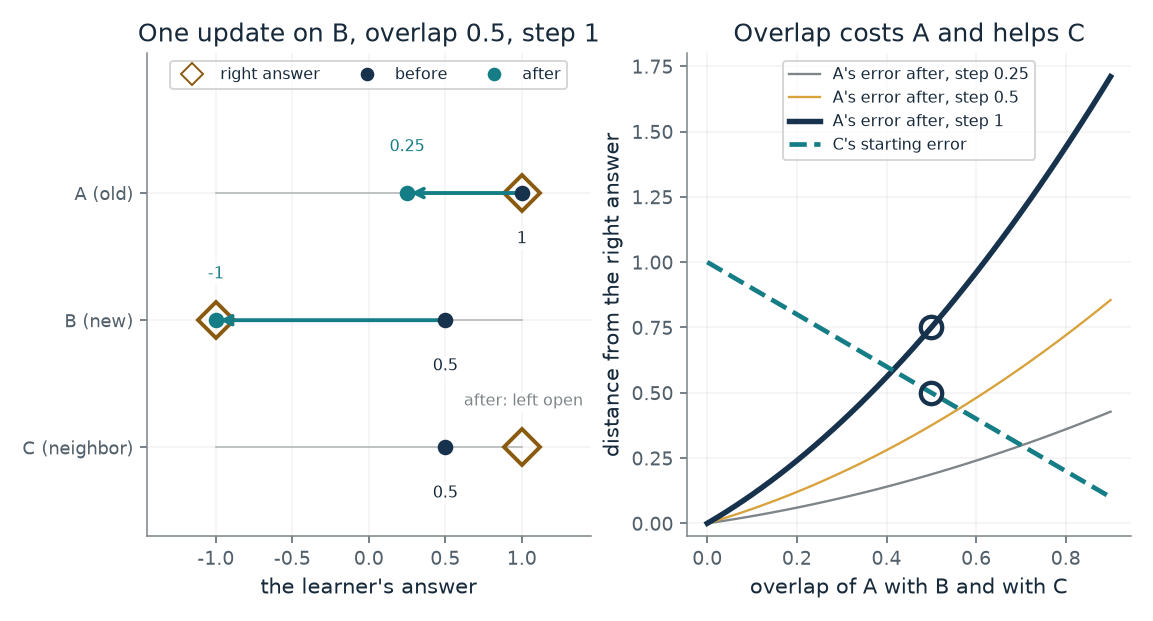

- **A's answer after:** 0.25
- **A's error after:** 0.75
- **C's answer before any update:** 0.5
- **C's error before any update:** 0.5

At overlap 0.5 and step 1, one update on B moves A's answer from 1 to 0.25, an error of 0.75. C starts 0.5 from its right answer, not 1, because it shares with A. C's change after the update is left open, as in the chapter.

B's error before = 0.5 + 1 = 1.5. A's answer after = 1 - 1 x 1.5 x 0.5 = 0.25. C's starting answer = 0.5, so its error is 1 - 0.5 = 0.5.

In [3]:
figure, values, explanation = price_and_point_picture(**{'overlap': 0.5, 'step': 1.0})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='What does overlap cost an old item and give a neighbor?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Overlap of A with B and with C = 0.5, Step size = 1.0: A's answer drops from 1 to 0.25, an error of 0.75. C already answers 0.5, an error of 0.5 instead of 1, because it shares half of A. With an overlap of 0, A is untouched but C gets no help from A.

**Takeaway:** Overlap is both the price and the point: the same sharing that drags an old answer off its value is what lets a neighbor borrow from it.

**Why it matters:** Keeping overlap low protects old answers but leaves items unable to teach each other. That is the trade behind mixing examples and behind the proposal that two memory systems code overlap differently.

**In brains and behavior:** McClelland and colleagues cite recordings in which fewer hippocampal cells fire than cells in the area feeding them. Sparse codes could let similar situations overlap little, with the neocortex as the slow learner that uses overlap. The paper marks this as a proposal, and the toy does not test it.

**In machines:** As McClelland and colleagues report French's 1991 work, keeping overlap low reduces interference, at the cost of 'a dramatic reduction in the exploitation of shared structure'. The toy shows the trade in one step for three constructed items.

**Where it applies:** A linear learner with unit-length feature lists whose weights start equal to A's features. C's answer after the update is not computed, because it depends on how C and B overlap and the chapter leaves that open. Steps below 1 leave B only partly learned.

**Check your understanding:** The overlap is 0.5 and the step is 1. What are A's answer and B's answer after the update?

<details><summary>Show the answer</summary>

B's error is 1.5, so B's answer moves from 0.5 to 0.5 - 1.5 = -1. A's answer is 1 - 1 x 1.5 x 0.5 = 0.25.

</details>

*Source: Chapter 7, A network taught only about penguins damaged what it knew about other birds. The chapter's constructed three-item toy: A answers 1, B's right answer is -1, C follows A's rule, all feature lists have length 1 and both overlaps are 0.5, so A falls from 1 to one quarter. The other overlaps and step sizes are the companion's. Figure 7.1 in the chapter is the same picture. Constructed, not data.*

## C07-D03: What does mixing old examples in buy, and what does it cost?

In a two-item toy, what happens to the old item A when the learner trains on the new item B alone, and what when old and new alternate?

With unit-length features each focused update on B shrinks B's error by the factor 1 - rate, and it drags A along by the overlap, so A ends off by overlap x (1 + overlap). Alternating updates are a projection method: they settle at the one weight list that answers both items exactly, which exists whenever the two feature lists differ.

$$
\mathbf w\leftarrow\mathbf w-\eta\,(\mathbf w\cdot\mathbf x_i-y_i)\,\mathbf x_i
$$

**Symbols:** w: the learner's weights; x_i, y_i: the features and right answer of the item being trained on, A or B; eta: the step size, called the rate here; overlap: the dot product of A's and B's features, as in the previous card

**Predict before looking:** Predict, for overlap 0.5 and rate 0.25, which schedule leaves A with the smaller error after 40 updates and which gets B below an error of 0.1 sooner.

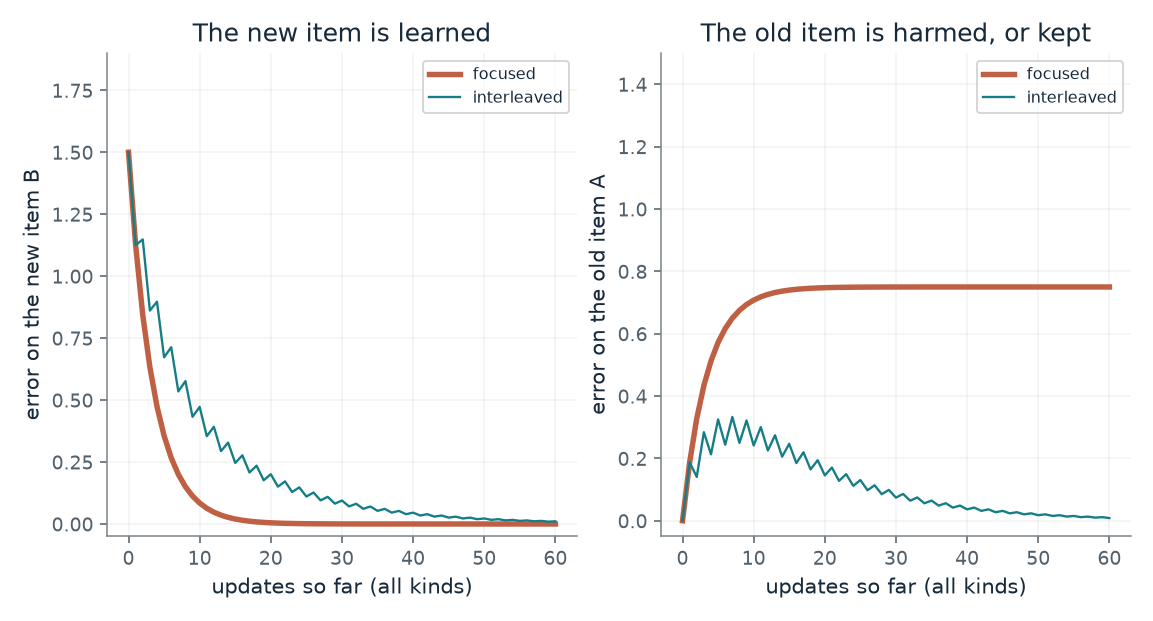

- **B error after 40 updates:** 1.51e-05
- **A error after 40 updates:** 0.75
- **Updates until B error is under 0.1:** 10
- **Largest A error in 60 updates:** 0.75

In this two-item toy with overlap 0.5 and rate 0.25, focused training: B is learned fast and A is left with an error of 0.75. It is a companion toy for the trade in the penguin network, not a copy of that network.

Each update subtracts rate x error x the item's features from the weights. Focused, with unit-length features, shrinks B's error by (1 - 0.25) each update and leaves A at 0.75 off in the limit. Interleaved settles at the weights that answer both exactly.

In [4]:
figure, values, explanation = schedule_picture(**{'schedule': 'focused', 'overlap': 0.5, 'rate': 0.25})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='What does mixing old examples in buy, and what does it cost?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Training schedule = focused, Overlap of A and B = 0.5, Rate = 0.25: Focused training gets B under 0.1 after 10 updates but leaves A off by 0.75. Interleaved training takes 27 updates to get B under 0.1, and A's error is only 0.037 after 40 updates. Faster for the new item, worse for the old one.

**Takeaway:** In the toy, training on the new item alone learns it fastest and harms the old item most, while mixing in the old item is slower per update and leaves very little harm.

**Why it matters:** This is the same trade the chapter reports for the penguin network, with the cost named: slower learning of each new fact and a person or process to choose the old examples to mix in.

**In brains and behavior:** The two-store proposal suggests that renewed activity from past events could give a slow learner mixed examples. Wilson and McNaughton found that pairs of cells that fired together awake fired together more in later sleep, and the 2010 ripple study cut ripples short; neither shows replay teaching a slow system.

**In machines:** McClelland and colleagues report that focused penguin training learned the new facts much more rapidly but treated all animals as swimmers that cannot fly, while mixed teaching was slower and caused very little harm. This toy only echoes that contrast.

**Where it applies:** A linear learner with unit-length features that starts exactly right on A. Focused training updates only on B. Interleaved training alternates B and A, so half its updates go to the old item and its progress is counted in updates of every kind. The chapter's network is nonlinear and far larger.

**Check your understanding:** With overlap 0.5 and rate 1, how far off is A after a single focused update on B, and after enough interleaved updates?

<details><summary>Show the answer</summary>

A single full focused update leaves A at an error of 0.5 x 1.5 = 0.75. After enough interleaved updates both errors approach 0, because the weights approach the exact solution for A and B.

</details>

*Source: Chapter 7, A network taught only about penguins damaged what it knew about other birds. A companion toy that uses the same A and B as the previous card to mimic the chapter's contrast between focused and interleaved training. The chapter reports McClelland and colleagues' penguin network in words only, with no numbers, so none of its results are reproduced. The overlaps, rates and the 60 updates are made up and nothing is random.*

## C07-D04: How much of the first effort did relearning save?

If learning took one amount of effort and relearning took another, what share of the first effort was saved?

The numerator is the effort relearning did not need, L0 minus Lt. Dividing by L0 turns it into a share of the first effort: 0 when relearning takes as long as learning did, 1 when it takes none.

$$
S(t)=\frac{L_0-L_t}{L_0}
$$

**Symbols:** S(t): savings after a delay t: the share of the first learning effort that relearning saved; L_0: the effort to learn the list the first time; L_t: the effort to relearn it after the delay, on the same material and the same stopping standard

**Predict before looking:** Learning a list took 25 repetitions and relearning it took 20. Predict the savings, and then the savings for a failed model that recovers with one twentieth of the original training.

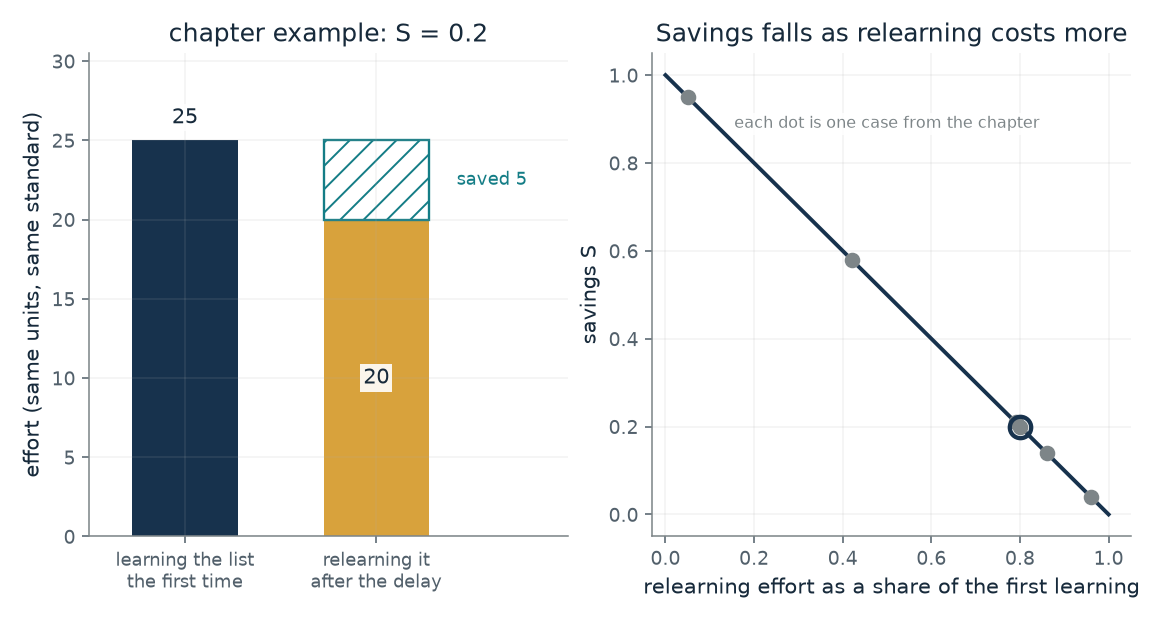

- **Savings S:** 0.2
- **Effort to learn first time:** 25
- **Effort to relearn:** 20
- **Effort saved:** 5

With a first learning effort of 25, savings of 0.2 means relearning takes 20, so 5 of the first effort is saved. For the reported savings values, the efforts are the companion's scaling, not data.

S = (L0 - Lt) / L0 = (25 - 20) / 25 = 0.2. Equivalently Lt = L0 x (1 - S) = 25 x 0.8 = 20.

In [5]:
figure, values, explanation = savings_picture(**{'case': 'chapter example', 'l0': 25})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='How much of the first effort did relearning save?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Case = chapter example, Effort of the first learning = 25: Five of 25 repetitions were saved, so S = 0.2. The one-twentieth model would have S = 0.95. The reported values on this card are Ebbinghaus's 0.58 and 0.21 and Murre and Dros's 0.04 and 0.14.

**Takeaway:** Savings counts the effort that relearning did not need, so a list that seems forgotten can still leave a large saving: forgetting need not be erasure.

**Why it matters:** A system that fails an exact-answer test may still be quick to restore. Savings asks how much of the first effort survived, which a recall test alone does not.

**In brains and behavior:** Ebbinghaus tested only himself, in 163 double tests in 1879 and 1880. Murre and Dros repeated the work with one subject, the second author, concluded the curve was replicated, and found far lower 31-day savings: about 0.04, or about 0.14 adjusted for a rise in learning time.

**In machines:** French's review reports that Hetherington and Seidenberg applied a savings measure to networks and found that a network that seemed to have forgotten could often be retrained quickly, though later work showed not all catastrophic forgetting is this shallow. No figures are given.

**Where it applies:** Both efforts are in the same units, on the same material and with the same stopping standard. The six cases are separate points and not a forgetting curve; the chapter gives only two of Ebbinghaus's values, so nothing is drawn between them. The one-twentieth model is the chapter's illustration, not a reported result. Savings alone does not show what a model's weights retain.

**Check your understanding:** A failed model recovers with one twentieth of its original training. What are the savings?

<details><summary>Show the answer</summary>

L_t is one twentieth of L_0, so S = (1 - 1/20) = 0.95.

</details>

*Source: Chapter 7, Forgotten lists were still relearned faster. The chapter's savings formula and worked example (25 repetitions, 20 on relearning). Ebbinghaus's 0.58 after minutes and 0.21 after a month, Murre and Dros's one-subject 31-day savings of about 0.04 (about 0.14 adjusted) and the one-twentieth model are as the chapter reports them. Ebbinghaus used his own formula, not the plain ratio, so the efforts shown for the reported savings are the companion's scaling to the chosen first effort, not data.*

## C07-D05: Can a prediction change without erasing an old expectation?

If a learner keeps two expectations, one from the old cause and one from a new cause, how does the combined prediction move when the weights change?

The combined prediction is a weighted average of the two causes' own predictions. The weights are the learner's current belief about which cause is active, so a change of setting that shifts the belief shifts the average, and the causes' expectations are untouched.

$$
\hat p=w_{\text{old}}\,p_{\text{old}}+w_{\text{new}}\,p_{\text{new}},\qquad w_{\text{old}}+w_{\text{new}}=1
$$

**Symbols:** w_old, w_new: the weights on the old and the new hidden cause, adding to 1; p_old: the old cause's chance of shock (1 here); p_new: the new cause's chance of shock (0 in the chapter); p_hat: the combined predicted chance of shock

**Predict before looking:** The old cause has weight 0.8 and predicts shock with probability 1; the new cause has weight 0.2 and predicts 0. Predict the combined prediction, and then what happens if the weights swap.

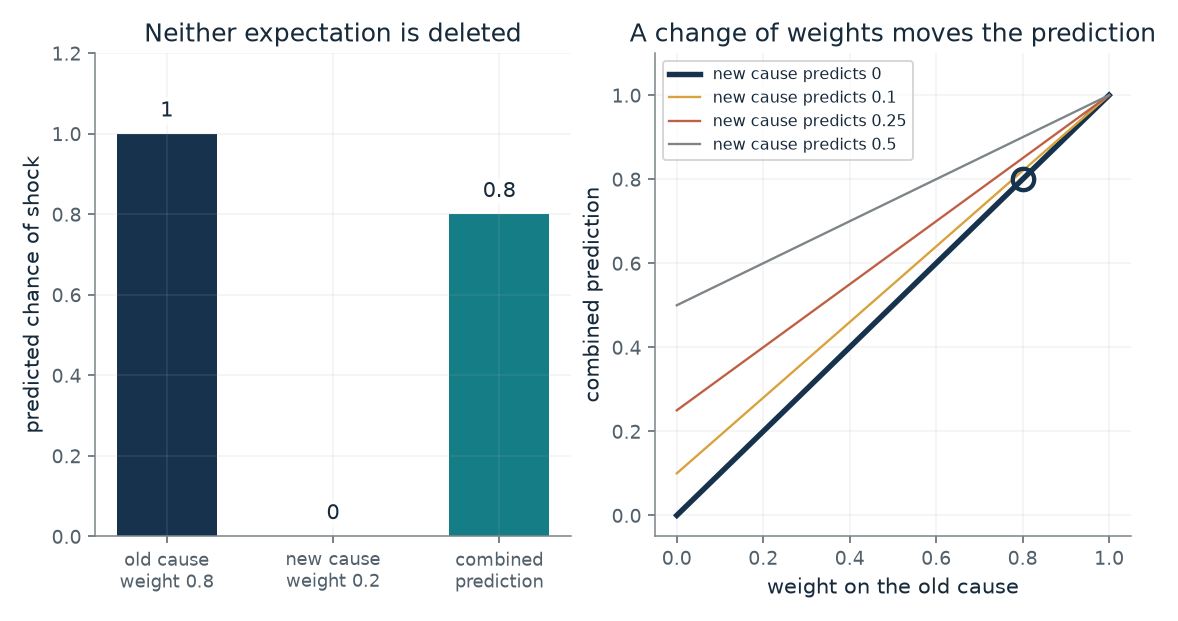

- **Weight on the old cause:** 0.8
- **Weight on the new cause:** 0.2
- **Combined prediction:** 0.8
- **New cause's own prediction:** 0

With weight 0.8 on the old cause, which predicts shock with probability 1, and 0.2 on a new cause that predicts 0, the combined prediction is 0.8. Changing the weights moves the prediction without changing either cause's own expectation. The weights are set by hand here, not inferred.

0.8 x 1 + 0.2 x 0 = 0.8.

In [6]:
figure, values, explanation = latent_cause_picture(**{'weight_old': 0.8, 'new_predicts': 0})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='Can a prediction change without erasing an old expectation?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Weight on the old cause = 0.8, New cause's chance of shock = 0: 0.8 x 1 + 0.2 x 0 = 0.8. With the weights swapped, 0.2 on the old cause, the prediction is 0.2. Neither expectation was deleted or changed, only the weights.

**Takeaway:** A change in which cause is thought to be active can move the prediction a long way without deleting either stored expectation.

**Why it matters:** This is a different answer to interference from overwriting shared connections: keep competing predictions and let evidence about the situation weigh them. Renewal after extinction is the kind of result it is meant to fit.

**In brains and behavior:** Bouton and Bolles's rats suppressed activity and bar pressing for a cue paired with shock, the response fell when the cue came without shock in another setting, and it returned when the rats went back to the first setting. One interpretation is that extinction adds learning that competes with the original; the result does not prove two separate physical memories.

**In machines:** A machine could preserve competing predictions and use evidence about the situation to weigh them. The chapter calls this an analogy, not a result from the rat experiment.

**Where it applies:** Two causes with fixed expectations and weights set by hand. This is a model of inference, not a measurement of the rat's thoughts, and the example does not prove that two separate physical memories exist or that the old memory never changes.

**Check your understanding:** The old cause has weight 0.7 and predicts shock with probability 1. The new cause predicts 0.1. What is the combined prediction?

<details><summary>Show the answer</summary>

0.7 x 1 + 0.3 x 0.1 = 0.7 + 0.03 = 0.73.

</details>

*Source: Chapter 7, A quiet response can hide an older memory. The chapter's constructed example of the latent-cause model's logic: weights 0.8 and 0.2, causes that predict shock with probabilities 1 and 0, and a combined prediction of 0.8. Gershman and colleagues' model infers the weights from the observations and their timing; here they are set by hand. The other values of the new cause's prediction are the companion's. Constructed, not data.*

## Bring it to your own question

Ask which old items share features with the new lesson, how large the step and the new error are, and whether the old answer actually became worse against its own target. Use the interference card for one step, the three-item card for the price and the point of overlap, the schedule card for focused against mixed training in a toy, the savings card to ask whether apparent loss is cheap to restore, and the mixture card for keeping competing expectations. Say that none of these is a measurement of a brain or of a deep network.

Use the `mmi-ch07-learning-without-losing` skill to choose a relevant equation, work with your inputs, and interpret the result. The skill should explain the assumptions and distinguish an illustration from evidence about your particular situation.